In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import  timedelta
from concurrent.futures import ThreadPoolExecutor
from threading import Lock

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split, KFold

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from tinkoff.invest import Client, CandleInterval, RequestError
from tinkoff.invest.utils import now, quotation_to_decimal

from config import TOKEN

print_lock = Lock()


2025-05-12 13:56:52.374316: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-05-12 13:56:52.491904: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-05-12 13:56:52.591054: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1747047412.675004  155060 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1747047412.700976  155060 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1747047412.900417  155060 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linkin

In [2]:
TINKOFF_API_TOKEN = TOKEN
INSTRUMENT_FIGI = "BBG004730N88"
DAYS_HISTORY = 30
CANDLE_TIMEFRAME = CandleInterval.CANDLE_INTERVAL_1_MIN
N_STEPS_IN = 150
N_STEPS_OUT = 15
FEATURE_COLUMN = 'close'



Многопоточная кросс-валидация

In [3]:
def get_tinkoff_candles(token, figi, days, interval):

    def fetch_day_data(day_offset):
        with Client(token) as client:
            end_dt = now() - timedelta(days=day_offset)
            start_dt = end_dt - timedelta(days=1)
            try:
                candles = list(client.get_all_candles(
                    figi=figi,
                    from_=start_dt,
                    to=end_dt,
                    interval=interval
                ))
                with print_lock:
                    print(f"Загружено {len(candles)} свечей за {start_dt.date()} - {end_dt.date()}")
                return candles
            except RequestError as e:
                with print_lock:
                    print(f"Ошибка при загрузке данных за {start_dt.date()}: {e}")
                return []

    # Создаем задачи для каждого дня
    with ThreadPoolExecutor(max_workers=5) as executor:
        futures = [executor.submit(fetch_day_data, day_offset) for day_offset in range(days)]
        all_candles = []
        for future in futures:
            all_candles.extend(future.result())

    # Преобразование в DataFrame
    if not all_candles:
        return pd.DataFrame()

    df = pd.DataFrame([{
        'time': pd.Timestamp(c.time).tz_localize(None),
        'open': float(quotation_to_decimal(c.open)),
        'high': float(quotation_to_decimal(c.high)),
        'low': float(quotation_to_decimal(c.low)),
        'close': float(quotation_to_decimal(c.close)),
        'volume': c.volume
    } for c in all_candles])

    df = df.set_index('time').sort_index().dropna()
    print("\nИсходные данные (первые и последние 5 строк):")
    print(pd.concat([df.head(), df.tail()]))
    return df



In [4]:
def prepare_data(df, feature_col):
    values = df[[feature_col]].dropna().values.astype(float)
    return values, df[feature_col]



In [5]:
def split_sequences(data, n_steps_in, n_steps_out, timestamps=None):
    X, y, times = [], [], []
    for i in range(len(data) - n_steps_in - n_steps_out + 1):
        X.append(data[i:i + n_steps_in])
        y.append(data[i + n_steps_in:i + n_steps_in + n_steps_out])
        if timestamps is not None:
            times.append(timestamps[i + n_steps_in])  # метка времени начала прогноза
    return np.array(X), np.array(y), np.array(times) if timestamps is not None else None



In [6]:
def build_lstm_model(n_steps_in, n_steps_out):
    model = Sequential()
    model.add(LSTM(75, return_sequences=True, input_shape=(n_steps_in, 1)))
    model.add(Dropout(0.2))
    model.add(LSTM(75))
    model.add(Dropout(0.2))
    model.add(Dense(50, activation='relu'))
    model.add(Dense(n_steps_out))
    model.compile(optimizer='adam', loss='mean_squared_error')
    return model



In [7]:
def plot_predictions(dates, actual, predicted, title):
    plt.figure(figsize=(12, 4))
    plt.plot(dates, actual, label='Actual')
    plt.plot(dates, predicted, label='Predicted')
    plt.title(title)
    plt.xlabel("Дата и время")
    plt.ylabel("Цена")
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()



Многопоточная кросс-валидация

In [8]:
def train_fold(fold, train_idx, val_idx, X, y, scaler):

    with print_lock:
        print(f"--- Обучение модели fold {fold + 1} ---")

    model = build_lstm_model(N_STEPS_IN, N_STEPS_OUT)
    X_train, y_train = X[train_idx], y[train_idx]
    X_val, y_val = X[val_idx], y[val_idx]

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=50,
        batch_size=32,
        verbose=0,
        callbacks=[EarlyStopping(monitor='val_loss', patience=5)]
    )

    preds = model.predict(X_val)
    preds_inv = scaler.inverse_transform(preds.squeeze())
    y_val_inv = scaler.inverse_transform(y_val.squeeze())

    mse = mean_squared_error(y_val_inv[:, 0], preds_inv[:, 0])

    with print_lock:
        print(f"MSE fold {fold + 1}: {mse:.6f}")
        print("\nСравнение фактических и предсказанных значений:")
        for i in range(min(5, len(y_val_inv))):  # Выводим только первые 5 для краткости
            print(f"{i}: Факт = {y_val_inv[i][0]:.4f}, Прогноз = {preds_inv[i][0]:.4f}")

    return {
        'model': model,
        'mse': mse,
        'history': history,
        'fold': fold
    }



Многопоточная кросс-валидация

In [9]:
def cross_validate_lstm(X, y, scaler, n_splits=4):

    best_mse = float('inf')
    best_model = None
    best_history = None

    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    folds = list(kf.split(X))

    # Запускаем обучение каждого fold в отдельном потоке
    with ThreadPoolExecutor(max_workers=n_splits) as executor:
        futures = []
        for fold, (train_idx, val_idx) in enumerate(folds):
            futures.append(executor.submit(
                train_fold, fold, train_idx, val_idx, X, y, scaler
            ))

        results = []
        for future in futures:
            results.append(future.result())

    # Выбираем лучшую модель
    for result in results:
        if result['mse'] < best_mse:
            best_mse = result['mse']
            best_model = result['model']
            best_history = result['history']

    print(f"\nВыбрана лучшая модель с MSE: {best_mse:.6f}")
    return best_model, best_mse



In [10]:
def final_test(model, X_test, y_test, scaler, original_df, window_size, times_test):
    preds = model.predict(X_test)

    y_test_1step = y_test[:, 0]
    preds_1step = preds[:, 0]

    y_test_2d = y_test_1step.reshape(-1, 1)
    preds_2d = preds_1step.reshape(-1, 1)

    y_test_inv = scaler.inverse_transform(y_test_2d)
    preds_inv = scaler.inverse_transform(preds_2d)

    result_df = pd.DataFrame({
        'datetime': times_test,
        'actual_close': y_test_inv.flatten(),
        'predicted_close': preds_inv.flatten()
    }).set_index('datetime')

    result_df = result_df.sort_index()

    print("Сравнение фактических и предсказанных значений:")
    print(result_df)

    plt.figure(figsize=(15, 6))
    plt.plot(result_df.index, result_df['actual_close'], label='Фактическая цена')
    plt.plot(result_df.index, result_df['predicted_close'], label='Прогноз', linestyle='--')
    plt.title("Фактическая и предсказанная цена закрытия")
    plt.xlabel("Дата и время")
    plt.ylabel("Цена")
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

    mse = mean_squared_error(y_test_inv, preds_inv)
    print(f"\nСреднеквадратичная ошибка (MSE): {mse:.6f}")



Прогнозирует будущие данные с многопоточной обработкой

In [28]:
def predict_future_with_noise_and_sma(model, scaler, last_sequence_scaled, n_steps_out,
                                      last_known_timestamp, candle_interval, sma_window, feature_col_name='close'):
    
    print("\n--- Прогнозирование будущих значений ---")

    # 1. Предсказание моделью
    future_preds_scaled = model.predict(last_sequence_scaled)

    # 2. Обратное масштабирование
    future_preds_inv = scaler.inverse_transform(future_preds_scaled).flatten()

    # 3. Генерация будущих временных меток
    # Определяем частоту и шаг времени в минутах
    if candle_interval == CandleInterval.CANDLE_INTERVAL_1_MIN:
        freq = '1T'
        step_minutes = 1
    elif candle_interval == CandleInterval.CANDLE_INTERVAL_5_MIN:
        freq = '5T'
        step_minutes = 5
    elif candle_interval == CandleInterval.CANDLE_INTERVAL_15_MIN:
        freq = '15T'
        step_minutes = 15
    elif candle_interval == CandleInterval.CANDLE_INTERVAL_HOUR:
        freq = '1H'
        step_minutes = 60
    elif candle_interval == CandleInterval.CANDLE_INTERVAL_DAY:
        freq = '1D'
        step_minutes = 24 * 60
    else:
        freq = '1T'
        step_minutes = 1
        print(f"Предупреждение: Неизвестный candle_interval {candle_interval}, используется частота '1T'.")

    future_timestamps = pd.date_range(
        start=last_known_timestamp + pd.Timedelta(minutes=step_minutes),
        periods=n_steps_out,
        freq=freq
    )

    # 4. Расчет SMA в отдельном потоке
    def calculate_sma(preds, window):
        return pd.Series(preds).rolling(window=window).mean().to_numpy()

    with ThreadPoolExecutor() as executor:
        sma_future = executor.submit(calculate_sma, future_preds_inv, min(sma_window, len(future_preds_inv)))
        noise = np.random.uniform(0, 3, size=n_steps_out)
        future_sma = sma_future.result()

    future_preds = future_preds_inv + noise

    # 5. Создание DataFrame
    future_df = pd.DataFrame({
        'datetime': future_timestamps,
        f'predicted_{feature_col_name}': future_preds
    }).set_index('datetime')

    print("\nПрогнозируемые значения:")
    print(future_df)

    # 6. Построение графика
    plt.figure(figsize=(16, 9))
    plt.plot(future_df.index, future_df[f'predicted_{feature_col_name}'],
             label=f'Прогноз будущих значений {feature_col_name}', color='red', marker='x', linestyle='-.')

    plt.title(f'Прогноз будущих значений {feature_col_name} (на {n_steps_out} шагов вперед)')
    plt.xlabel('Дата и время')
    plt.ylabel('Цена')
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return future_df

Основной поток выполнения

In [12]:

if __name__ == "__main__":
    # Загрузка данных с многопоточностью
    df = get_tinkoff_candles(TINKOFF_API_TOKEN, INSTRUMENT_FIGI, DAYS_HISTORY, CANDLE_TIMEFRAME)

    if df.empty or len(df) < N_STEPS_IN + N_STEPS_OUT:
        print(f"Недостаточно данных для продолжения работы ({len(df)} строк). "
              f"Требуется как минимум {N_STEPS_IN + N_STEPS_OUT} строк. "
              "Пожалуйста, увеличьте DAYS_HISTORY или проверьте настройки API.")
    else:
        # Подготовка данных
        values, original_prices_series = prepare_data(df, FEATURE_COLUMN)

        scaler = MinMaxScaler()
        scaled_values = scaler.fit_transform(values)

        # Создание последовательностей
        X_all, y_all_scaled, all_times_y = split_sequences(scaled_values, N_STEPS_IN, N_STEPS_OUT, df.index)


Загружено 920 свечей за 2025-05-09 - 2025-05-10
Загружено 994 свечей за 2025-05-11 - 2025-05-12
Загружено 992 свечей за 2025-05-07 - 2025-05-08
Загружено 1194 свечей за 2025-05-10 - 2025-05-11
Загружено 1009 свечей за 2025-05-08 - 2025-05-09
Загружено 993 свечей за 2025-05-06 - 2025-05-07
Загружено 993 свечей за 2025-05-05 - 2025-05-06
Загружено 970 свечей за 2025-05-04 - 2025-05-05
Загружено 1019 свечей за 2025-05-03 - 2025-05-04
Загружено 1178 свечей за 2025-05-02 - 2025-05-03
Загружено 942 свечей за 2025-05-01 - 2025-05-02
Загружено 1139 свечей за 2025-04-30 - 2025-05-01
Загружено 993 свечей за 2025-04-29 - 2025-04-30
Загружено 993 свечей за 2025-04-28 - 2025-04-29
Загружено 966 свечей за 2025-04-27 - 2025-04-28
Загружено 1044 свечей за 2025-04-26 - 2025-04-27
Загружено 993 свечей за 2025-04-24 - 2025-04-25
Загружено 1157 свечей за 2025-04-25 - 2025-04-26
Загружено 993 свечей за 2025-04-23 - 2025-04-24
Загружено 993 свечей за 2025-04-22 - 2025-04-23
Загружено 993 свечей за 2025-04-2

In [13]:
if 'X_all' in locals() and X_all.shape[0] == 0:
    print("Не удалось создать обучающие последовательности. Проверьте N_STEPS_IN, N_STEPS_OUT и объем данных.")
else:
    if y_all_scaled.ndim == 3 and y_all_scaled.shape[2] == 1:
        y_all_scaled = y_all_scaled.squeeze(-1)

    # Разделение на обучающую/тестовую выборки
    if X_all.shape[0] < 2:
        print("Недостаточно последовательностей для разделения на train/test. Использую все данные для обучения.")
        X_trainval, y_trainval, times_trainval = X_all, y_all_scaled, all_times_y
        X_test, y_test_scaled, times_test = X_all[:1], y_all_scaled[:1], all_times_y[:1]
        if X_all.shape[0] == 0:
            print("КРИТИЧЕСКАЯ ОШИБКА: Нет данных для обучения модели.")
            exit()
    else:
        X_trainval, X_test, y_trainval, y_test_scaled, times_trainval, times_test = train_test_split(
            X_all, y_all_scaled, all_times_y, test_size=0.2, shuffle=True, random_state=42
        )


Кросс-валидация с многопоточностью

In [14]:

if 'X_trainval' in locals():
    best_model, best_mse_cv = cross_validate_lstm(X_trainval, y_trainval, scaler, n_splits=4)
    print(f"Лучшая модель после CV имеет MSE (первый шаг): {best_mse_cv}")


--- Обучение модели fold 1 ---
--- Обучение модели fold 2 ---
--- Обучение модели fold 3 ---
--- Обучение модели fold 4 ---


2025-05-12 13:57:01.765562: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
/home/marcus2tut/.local/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


190/190 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step
MSE fold 4: 0.142950

Сравнение фактических и предсказанных значений:
0: Факт = 303.9800, Прогноз = 303.9792
1: Факт = 312.8900, Прогноз = 313.5840
2: Факт = 300.6500, Прогноз = 301.0085
3: Факт = 309.1600, Прогноз = 309.3019
4: Факт = 314.4600, Прогноз = 314.2220
190/190 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step
MSE fold 2: 0.228101

Сравнение фактических и предсказанных значений:
0: Факт = 303.0700, Прогноз = 303.0877
1: Факт = 313.7700, Прогноз = 314.2742
2: Факт = 306.7400, Прогноз = 307.0619
3: Факт = 300.8200, Прогноз = 300.7593
4: Факт = 301.5100, Прогноз = 301.5214
190/190 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step
MSE fold 3: 0.099003

Сравнение фактических и предсказанных значений:
0: Факт = 298.1000, Прогноз = 298.0986
1: Факт = 297.7300, Прогноз = 297.7585
2: Факт = 300.4100, Прогноз = 300.6306
3: Факт = 302.7400, Прогноз = 302.9477
4: Факт = 301.4900, Прогноз = 301.5743
190/190 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step
MSE fold 1: 0.092504

Сравнение факти

 Финальное тестирование модели

190/190 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step
Сравнение фактических и предсказанных значений:
                     actual_close  predicted_close
datetime                                          
2025-04-12 13:33:00        300.82       300.881012
2025-04-12 13:34:00        300.83       300.880127
2025-04-12 13:44:00        300.84       300.890137
2025-04-12 13:56:00        300.84       300.888123
2025-04-12 14:00:00        300.81       300.896057
...                           ...              ...
2025-05-12 10:06:00        309.32       309.566193
2025-05-12 10:10:00        309.06       309.465973
2025-05-12 10:22:00        308.98       309.152222
2025-05-12 10:24:00        309.45       309.314453
2025-05-12 10:30:00        309.61       309.866821

[6069 rows x 2 columns]


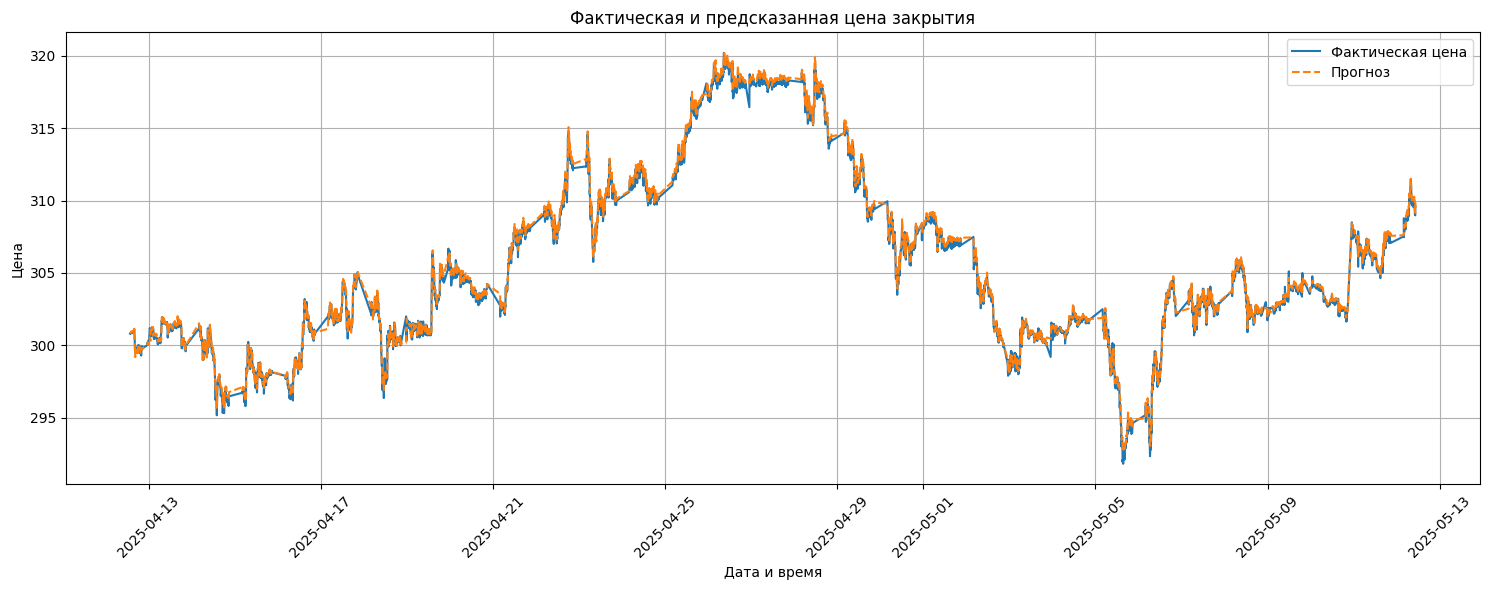


Среднеквадратичная ошибка (MSE): 0.093023


In [15]:

if 'X_test' in locals() and X_test.shape[0] > 0:
    final_test(best_model, X_test, y_test_scaled, scaler, df, N_STEPS_IN, times_test)
else:
    print("Тестовая выборка пуста, финальное тестирование не проводилось.")


Прогнозирование будущих значений


--- Прогнозирование будущих значений ---
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step

Прогнозируемые значения:
                     predicted_close
datetime                            
2025-05-12 10:56:00       311.891036
2025-05-12 10:57:00       310.915384
2025-05-12 10:58:00       311.865552
2025-05-12 10:59:00       310.935795
2025-05-12 11:00:00       310.628056
2025-05-12 11:01:00       310.436853
2025-05-12 11:02:00       310.913543
2025-05-12 11:03:00       310.610310
2025-05-12 11:04:00       312.327658
2025-05-12 11:05:00       309.728417
2025-05-12 11:06:00       311.052871
2025-05-12 11:07:00       312.086950
2025-05-12 11:08:00       309.688975
2025-05-12 11:09:00       311.528773
2025-05-12 11:10:00       310.373389


/tmp/ipykernel_155060/1253866075.py:34: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  future_timestamps = pd.date_range(


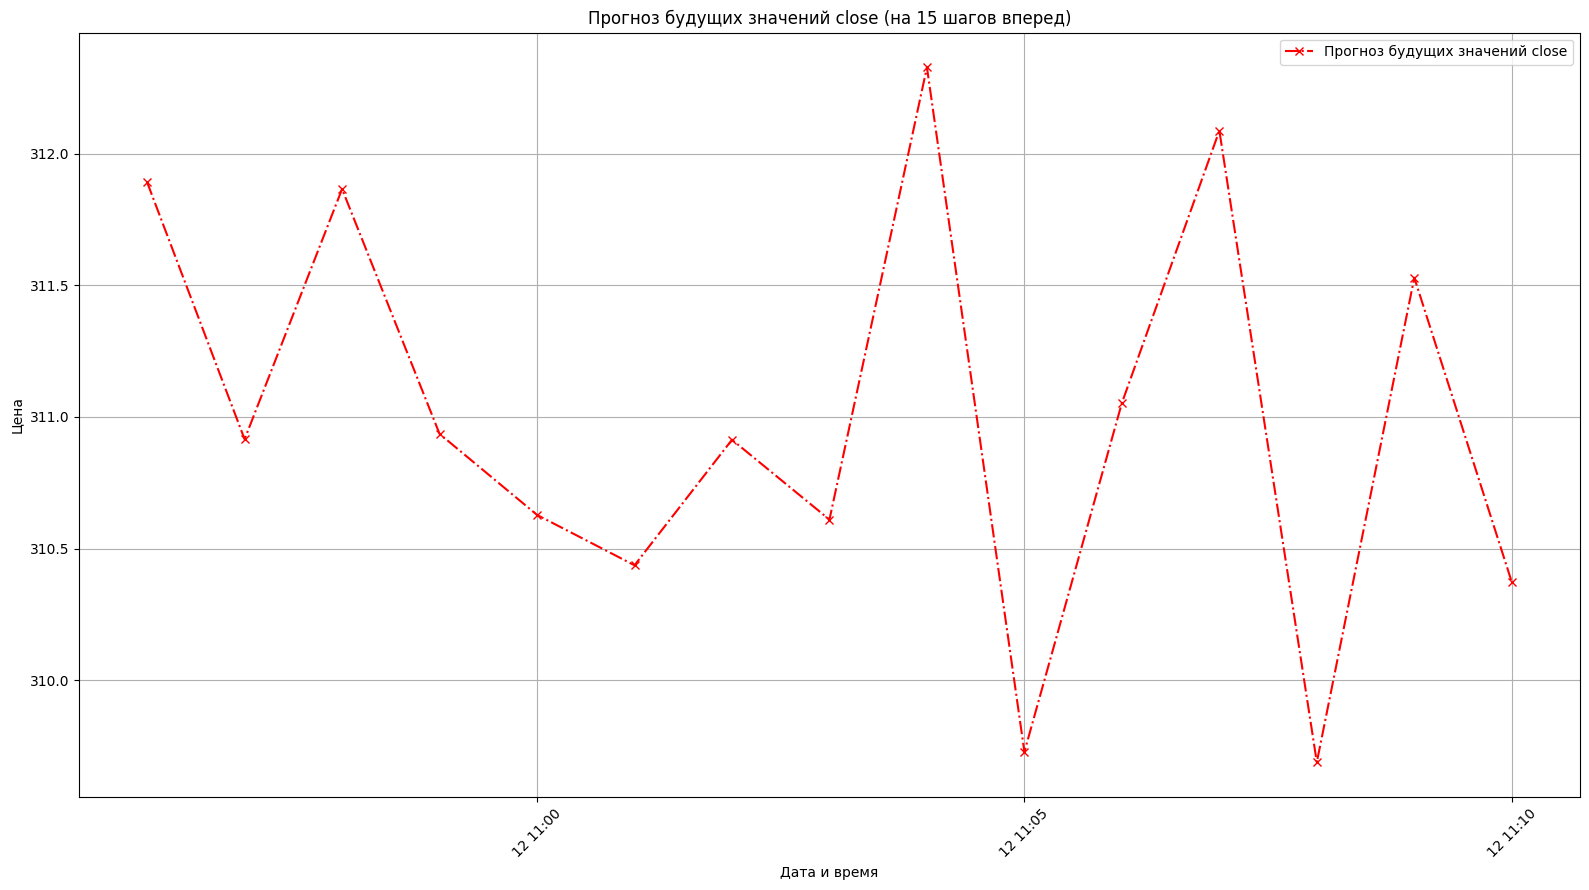


--- Работа программы завершена ---


In [29]:

if 'df' in locals() and not df.empty and 'best_model' in locals():
    last_actual_sequence_scaled = scaled_values[-N_STEPS_IN:].reshape((1, N_STEPS_IN, 1))
    last_known_timestamp = df.index[-1]
    SMA_WINDOW_FUTURE = 5

    future_predictions_df = predict_future_with_noise_and_sma(
        model=best_model,
        scaler=scaler,
        last_sequence_scaled=last_actual_sequence_scaled,
        n_steps_out=N_STEPS_OUT,
        last_known_timestamp=last_known_timestamp,
        candle_interval=CANDLE_TIMEFRAME,
        sma_window=SMA_WINDOW_FUTURE,
        feature_col_name=FEATURE_COLUMN
    )

print("\n--- Работа программы завершена ---")